## Networkscience Enzyme Investigation
 
 

In [34]:
# importing all the libraries
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter
from scipy.stats import poisson
from matplotlib.colors import LinearSegmentedColormap
from networkx.algorithms.community import louvain_communities, modularity, greedy_modularity_communities
from sklearn.metrics import normalized_mutual_info_score as nmi

In [7]:
# Reading the data and sumamrizing pairs that go in both directions into one
edges = pd.read_csv("edgelist.txt", sep=r"\s+", header=None, names=["u", "v"])
G = nx.Graph() 
G.add_edges_from(edges.itertuples(index=False, name=None)) 
 
print("nodes", G.number_of_nodes(), "edges", G.number_of_edges())

nodes 51 edges 110


### Connectivity and structure:

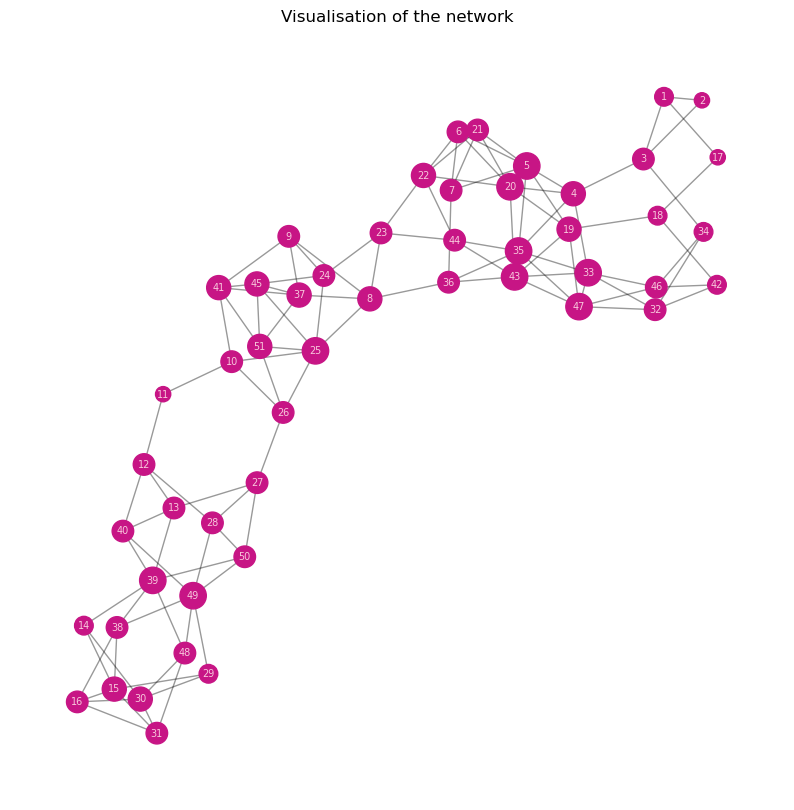

In [9]:
#Visualization of the Netowrk for intial inspection: 
position = nx.kamada_kawai_layout(G)
plt.figure(figsize=(10, 10))
nx.draw_networkx_edges(G, position, alpha=0.4) # draw all edges as lines at correct postions
nx.draw_networkx_nodes(G, position, node_size=[60 * G.degree(v) for v in G], node_color="#C71585") # size appears based on degree of the node
nx.draw_networkx_labels(G, position, font_size=7, font_color="#F8C8DC") # 
plt.title("Visualisation of the network")
plt.axis("off")
plt.savefig("network_overview.png", dpi=150, bbox_inches="tight")
plt.show()

Q: Connectivity and structure: What does the network look like at the global level? Are there features of its
connectivity or topology that are important for understanding the network?

A: Here it can be observed that the network is rather long as it is only on the diagonal of the visualisation. There are some rather dense bloks that are only connected with a few edges to others. There appears to be an upper and lower half of the graph, with a connection through nodes 10,11 and 12 as well as 26 and 27. Apart from that there are no obvious hubs apparent, most of the nodes seem to have similar degrees within a cvertain range. 

But lets look at some actual stats:

connected_components 1
density 0.086
average_degree 4.31
diameter 12 , radius 6 , center: [25]
node pairs with diameter 12 : 20
examplepath [2, 3, 4, 35, 36, 8, 25, 26, 27, 13, 39, 14, 15]
average pathlength 5.042


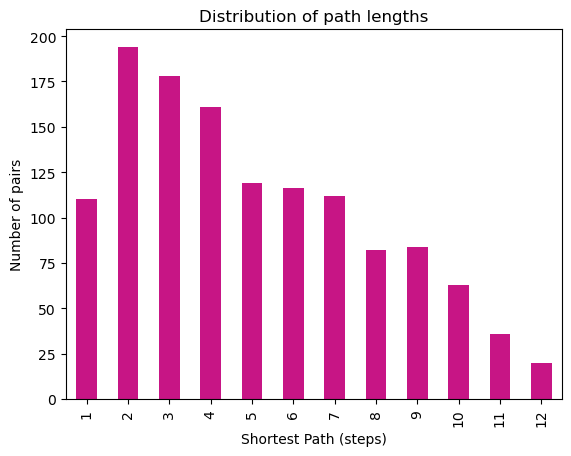

nodeconnectivity 2 , edgeconnectivity 2
articulation points []
bridges []
components after removing 11-12 and 26-27: [16, 35]
smaller component: [12, 13, 14, 15, 16, 27, 28, 29, 30, 31, 38, 39, 40, 48, 49, 50]
observed: mean 5.042 , diameter 12 , share of pairs with >= 7 steps 0.311
null: mean 2.796 ± 0.028 , range 2.736 to 2.871
null: diameter mean 5.09 , min 5 , max 6
             1      2      3      4      5      6      7     8     9     10    11    12
observed  110.0  194.0  178.0  161.0  119.0  116.0  112.0  82.0  84.0  63.0  36.0  20.0
null      110.0  331.0  559.9  258.0   16.0    0.1    0.0   0.0   0.0   0.0   0.0   0.0


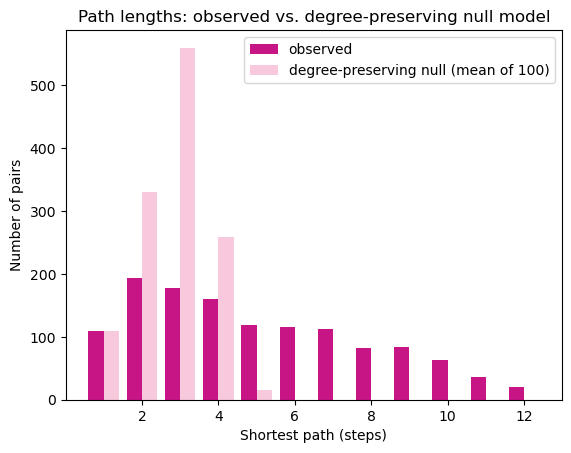

In [21]:
n, m = G.number_of_nodes(), G.number_of_edges()

print("connected_components", nx.number_connected_components(G))
print("density", round(nx.density(G), 3))
print("average_degree", round(2 * m / n, 2))

shortestpath = dict(nx.all_pairs_shortest_path_length(G))

D = nx.diameter(G)
print("diameter", D, ", radius", nx.radius(G), ", center:", nx.center(G))

far = [(a, b) for a in G for b in G if a < b and shortestpath[a][b] == D]
print("node pairs with diameter", D, ":", len(far))
print("examplepath", nx.shortest_path(G, *far[0]))


lengths = [shortestpath[a][b] for a in G for b in G if a < b]
print("average pathlength", round(np.mean(lengths), 3))
pd.Series(lengths).value_counts().sort_index().plot(kind="bar", color="#C71585")
plt.title("Distribution of path lengths")
plt.xlabel("Shortest Path (steps)")
plt.ylabel("Number of pairs")
plt.show()

print("nodeconnectivity", nx.node_connectivity(G),
      ", edgeconnectivity", nx.edge_connectivity(G))

print("articulation points", list(nx.articulation_points(G)))
print("bridges", list(nx.bridges(G)))
H = G.copy()
H.remove_edges_from([(11, 12), (26, 27)])
comps = sorted(nx.connected_components(H), key=len)
print("components after removing 11-12 and 26-27:", [len(c) for c in comps])
print("smaller component:", sorted(comps[0]))

## Comparison of null model with same degreesequence
null_mean, null_diam, null_counts = [], [], []
for s in range(100):
    H = G.copy()
    nx.connected_double_edge_swap(H, nswap=10 * m, seed=s)
    sp = dict(nx.all_pairs_shortest_path_length(H))
    L = [sp[a][b] for a in H for b in H if a < b]
    null_mean.append(np.mean(L))
    null_diam.append(max(L))
    null_counts.append(pd.Series(L).value_counts().reindex(range(1, 13), fill_value=0))

print("observed: mean", round(np.mean(lengths), 3), ", diameter", D,
      ", share of pairs with >= 7 steps", round(np.mean(np.array(lengths) >= 7), 3))
print("null: mean", round(np.mean(null_mean), 3), "±", round(np.std(null_mean), 3),
      ", range", round(min(null_mean), 3), "to", round(max(null_mean), 3))
print("null: diameter mean", np.mean(null_diam), ", min", min(null_diam), ", max", max(null_diam))

observed_counts = pd.Series(lengths).value_counts().reindex(range(1, 13), fill_value=0)
null_avg = pd.concat(null_counts, axis=1).mean(axis=1)
print(pd.DataFrame({"observed": observed_counts, "null": null_avg.round(1)}).T.to_string())

x = np.arange(1, 13)
plt.bar(x - 0.2, observed_counts.values, width=0.4, color="#C71585", label="observed")
plt.bar(x + 0.2, null_avg.values, width=0.4, color="#F8C8DC", label="degree-preserving null (mean of 100)")
plt.xlabel("Shortest path (steps)")
plt.ylabel("Number of pairs")
plt.title("Path lengths: observed vs. degree-preserving null model")
plt.legend()
plt.show()

Q: What does the network look like at the global level? Are there features of its
connectivity or topology that are important for understanding the network?

A: With the actual statistics we get a better overview:
connected_components 1: This tells us that we can reach every node from every node, and the whole network is connected there are no loose parts.

density 0.086, average_degree 4.31: It is a rather "thin" network out of all the connections or edges that could exist we have only 8.6% of them.  


diameter 12 , radius 6 , center: [25]: The longest shortest path is 12 steps long and the diameter is twice the radius which mathces the rather long form of the network and the center is also visually in the middle of the visualition.

average pathlength 5.042: This is rather long for only 51 nodes. In the Nullmodel we can see an average of 2.8.

Visualization of the distribution of path lengths: we can observe a long tail, most pairs have two steps and then it sowly decreases up to 12 at most.

articulation points [], bridges []: There are no articulation points and bridges, since there are no single nodes that could divide the whole component.

components after removing 11-12 and 26-27: [16, 35], smaller component: [12, 13, 14, 15, 16, 27, 28, 29, 30, 31, 38, 39, 40, 48, 49, 50]: This "proves" that there is an upper and lower half to the network.

Null model comparison: We have almost all pairs with 2-4 steps. The average pathlength is also shorter than in our enzyme network. So the "lenght" of the network is rather unusual compared to the null model. It has to be noted that it only controls the degree sequene, so it can be derived that the structure is not explained by its degrees, but not what produces the structure.



### Important or unusual nodes:

   degree  betweenness  closeness  eigenvector  pagerank
0       5            8          8           43        39
1      20           25         25           35        49
2      33           26         36           33        25
3      35           36         26           47        47
4      25           27         23           20        33
5      39           35         24            5         5
6      43           43         37            4        20
             degree  betweenness  closeness  eigenvector  pagerank
degree        1.000        0.374      0.389        0.418     0.919
betweenness   0.374        1.000      0.616        0.258     0.377
closeness     0.389        0.616      1.000        0.606     0.199
eigenvector   0.418        0.258      0.606        1.000     0.271
pagerank      0.919        0.377      0.199        0.271     1.000
Knoten mit Grad 6: [5, 20, 33, 35, 25, 39, 43, 47, 49]


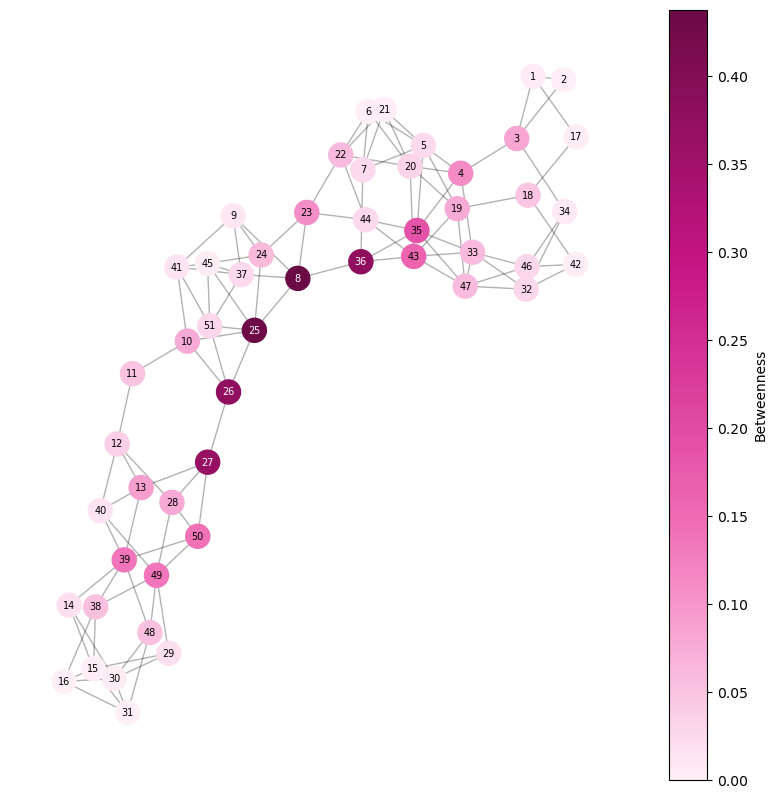

    betweenness
11        0.051
12        0.037
26        0.381
27        0.366


In [25]:
centrality = pd.DataFrame({
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G),
    "eigenvector": nx.eigenvector_centrality(G, max_iter=2000),
    "pagerank": nx.pagerank(G),
})

top7 = pd.DataFrame({c: centrality[c].nlargest(7).index.tolist() for c in centrality.columns})
print(top7)

print(centrality.corr(method="spearman").round(3))

degree = pd.Series(dict(G.degree()))
print("Knoten mit Grad 6:", degree[degree == 6].index.tolist())

b = centrality["betweenness"]
dark = [v for v in G if b[v] > 0.3]
light = [v for v in G if b[v] <= 0.3]


pink_cmap = LinearSegmentedColormap.from_list("pink_shades", ["#FFF0F8", "#F06CB5", "#C71585", "#6B0B45"])
plt.figure(figsize=(10, 10))
nx.draw_networkx_edges(G, position, alpha=0.3)
nodes = nx.draw_networkx_nodes(G, position, node_color=[b[v] for v in G], cmap=pink_cmap, node_size=300)
nx.draw_networkx_labels(G, position, labels={v: v for v in light}, font_size=7, font_color="black")
nx.draw_networkx_labels(G, position, labels={v: v for v in dark}, font_size=7, font_color="white")
plt.colorbar(nodes, label="Betweenness")
plt.axis("off")
plt.show()

print(centrality.loc[[11, 12, 26, 27], ["betweenness"]].round(3))

Q: Are some nodes structurally more important or unusual than others? Choose
appropriate measures of centrality or ranking, identify interesting nodes, and explain what makes them important or unusual. Consider whether different notions of importance lead to the same or different nodes.

A: When looking at the visualization the nodes 8, 25, 26, 36 and 27 are sticking out building sort of a chain through the whole network. They sort of mark a point in the network where the upper and lower half are connected through only a narrow link (the edges 11–12 and 26–27), and most paths betweeen the two halves need to pass through these edges and nodes. However they do not form a hub, 26, 36 and 27 have only degree 4. Thsi means that their importance comes from their positions between the upper and lower half and not their number of neighbours.

A node that specifically stands out is 25: it marks the centre of the network with radius 6, it ranks amongst the highest for betweeness, closeness and pagerank. It is thus important in several senses: centrality in terms of distances and because it lies on many paths.

Another intersting node is 8 it has only degree 5 but also ranks in the top 3 for betweenness and highest closeness. It connects the upper right block to the chain and is relatively close to all the other nodes.

We can also see with the spearman rank correlations, that pagerank is almost identical to the degree, the betweenness and closeness are only moderately related. The measures rank the nodes in different ways. Pagerank adds only little beyond the degree and betweenness and eigenvector centrality describe position between the parts vs. embedding in a dense block.

Explanations: degree (number of neighbours), betweenness (share of shortest paths passing through a node), closeness (average distance to all other nodes), eigenvector centrality (importance depends on the importance of the neighbours) and PageRank (stationary distribution of a random surfer). 



### Degree structure: 

count    51.000000
mean      4.313725
std       1.086098
min       2.000000
25%       4.000000
50%       4.000000
75%       5.000000
max       6.000000
dtype: float64
variance 1.18 variance and mean relationship 0.27


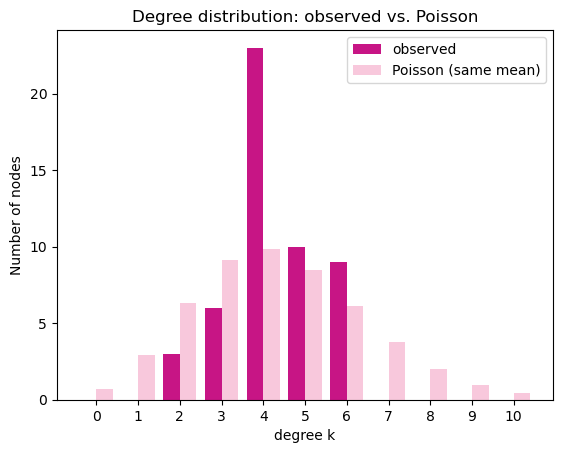

degree 2 [2, 17, 11]


In [27]:
print(degree.describe())
print("variance", round(degree.var(), 2), "variance and mean relationship", round(degree.var() / degree.mean(), 2))

ks = np.arange(0, 11)
observed = degree.value_counts().reindex(ks, fill_value=0)
expected = poisson.pmf(ks, degree.mean()) * n

plt.bar(ks - 0.2, observed.values, width=0.4, color="#C71585", label="observed")
plt.bar(ks + 0.2, expected, width=0.4, color="#F8C8DC", label="Poisson (same mean)")
plt.xticks(ks)
plt.xlabel("degree k")
plt.ylabel("Number of nodes")
plt.legend()
plt.title("Degree distribution: observed vs. Poisson")
plt.show()

print("degree 2", degree[degree == 2].index.tolist())

Q: What does the degree distribution reveal that cannot be inferred from the average degree
alone?

A: In the visualization we can observe a difference in the observed distribution of the network and the poisson distribution. Our network has degrees 2-6 and poisson has 0-10. The degree 4 sticks out in our network we observe 23 nodes compared to only 10 in the poisson distribution with the same mean. 

We can see that all nodes lie close to the mean from the std of 1.09 compared to 2.08 in the poisson distribution so almost twice as high. We have learned that the Erdos-Renyi model has very few hubs, this enzyme network has even less, since  degree distribution is rather narrow.

The mean degree alone does not distinguish between a network with a few hubs and many peripheral nodes and a very regular one. The distribution shows that this network is the regular type: all nodes have similar numbers of neighbours and there are no hubs. 


### Relationships between connected nodes: 

In [31]:
rel = nx.degree_assortativity_coefficient(G)

rel_null = []
for s in range(200):
    H = G.copy()
    nx.double_edge_swap(H, nswap=10 * m, max_tries=100 * m, seed=s)
    rel_null.append(nx.degree_assortativity_coefficient(H))

print("rel observed:", round(rel, 3))
print("rel nullmodel:", round(np.mean(rel_null), 3), "±", round(np.std(rel_null), 3))
print("z-value:", round((rel - np.mean(rel_null)) / np.std(rel_null), 2))

knn = pd.Series(nx.average_neighbor_degree(G))
print(pd.DataFrame({"k": degree, "knn": knn}).groupby("k").knn.mean().round(2))

pairs = pd.DataFrame([(degree[u], degree[v]) for u, v in G.edges()] +
                     [(degree[v], degree[u]) for u, v in G.edges()], columns=["k_u", "k_v"])
print(pd.crosstab(pairs.k_u, pairs.k_v))

print("share of null networks with r >= observed:", np.mean(np.array(rel_null) >= rel))
knn_null = []
for s in range(200):
    H = G.copy()
    nx.double_edge_swap(H, nswap=10 * m, max_tries=100 * m, seed=s)
    knn_null.append(pd.DataFrame({"k": degree, "knn": pd.Series(nx.average_neighbor_degree(H))}).groupby("k").knn.mean())

nl = pd.concat(knn_null, axis=1)
obs_knn = pd.DataFrame({"k": degree, "knn": knn}).groupby("k").knn.mean()
print(pd.DataFrame({"observed": obs_knn.round(2), "null mean": nl.mean(axis=1).round(2), "null std": nl.std(axis=1).round(2)}))

rel observed: 0.169
rel nullmodel: -0.021 ± 0.096
z-value: 1.98
k
2    3.50
3    4.06
4    4.64
5    4.66
6    4.70
Name: knn, dtype: float64
k_v  2  3   4   5   6
k_u                  
2    0  3   3   0   0
3    3  2   6   5   2
4    3  6  38  19  26
5    0  5  19  14  12
6    0  2  26  12  14
share of null networks with r >= observed: 0.02
   observed  null mean  null std
k                               
2      3.50       4.56      0.49
3      4.06       4.61      0.25
4      4.64       4.60      0.08
5      4.66       4.58      0.12
6      4.70       4.54      0.15


Q: Do nodes tend to connect to other nodes with similar or different
degrees? What does this tell you about the network’s organization?

A:
rel observed: 0.169 The assortativity coefficient shows the correlation of degrees between two endpoints of an edge. (-1 to 1). Here it is > 0 which means the nodes tend to connect to nodes of similar degrees but only with a weak tendency.

rel nullmodel: -0.021 ± 0.096: here we have a value below 0 with standard deviation of 0.096. This is a quite large variation since we have a rather small network.

z-value: 1.98: indicated how many std's the observed assortativity coefficient lies above the mean of the randomized null models. A value around two can be considered as a result that could be due to chance but not necessarily. So this cannot be interpreted as a clear finding. An empirical check agrees with this finding only four of the 200 randomised networks reach an assortativity coefficient at least as large as the observed one, which makes the effect rather unclear.

knn shows the average degree of the neighbours of nodes with a given degree. In this case we can observe that knn increases very slightly with k, this indicates that the network is tendig towards being assortative.

So overall we can cocnlude that there is only a weak tendency for the nodes to have connections to other nodes with similar degres. And that we have a not very conclusive result. So the connections are largely formed independent of the node degree and again we have no apparent organisation around hubs. This is also consitent with the narrow degree distribution, since there are also no dominant hubs. Comparing the knn with the null model shows that the weak assortativity is carried by the low-degree nodes (2 and 3: 3.50 and 4.06 vs 4.56 ± 0.49 and 4.61 ± 0.25 in randomised networks), whereas for degrees 4 to 6 the observed values (4.64 to 4.70) agree with the null model (about 4.6) so theperipheral nodes are observed to attach to other lower degree nodes however nodes of high degree do not necessarily connect to eachother.



### Local structure

total triangles 32
average clustering 0.238
transitivity 0.244
nodes with most triangles
 51    5
37    5
47    5
33    5
45    5
25    4
41    4
dtype: int64
highest clustering
 2     1.0
51    0.5
45    0.5
31    0.5
16    0.5
37    0.5
41    0.4
dtype: float64
nodes in no triangle [11, 14, 17, 18, 29, 34, 36, 42]
edges in no triangle 40 of 110
neck edges 26-27 and 11-12 in no triangle True True


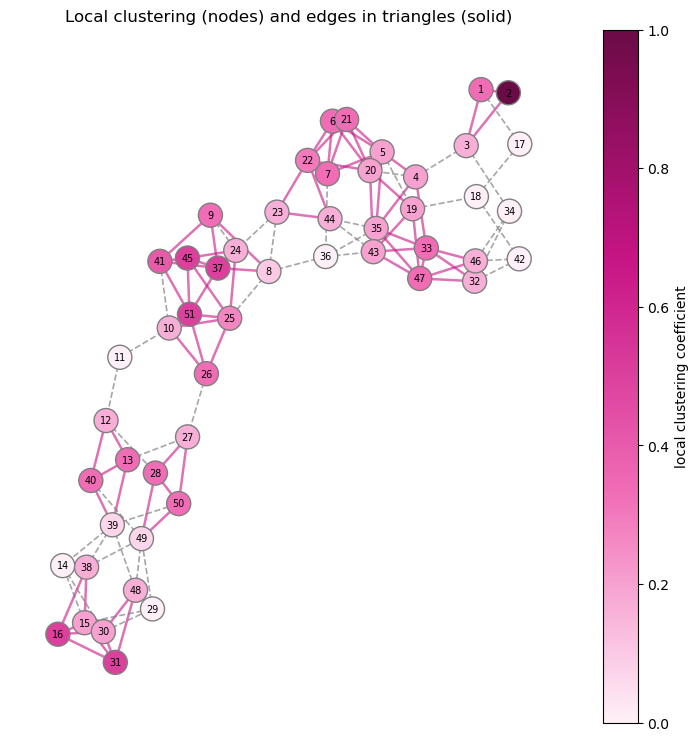

triangles: observed 32.000 | degree-preserving null 8.040 ± 2.630 (max 16.000) | random G(n,m) 12.940 ± 3.383
average clustering: observed 0.238 | degree-preserving null 0.061 ± 0.022 (max 0.127) | random G(n,m) 0.081 ± 0.026
transitivity: observed 0.244 | degree-preserving null 0.061 ± 0.020 (max 0.122)
share of null networks with at least as many triangles: 0.0
    degree  triangles  clustering
33       6          5       0.333
47       6          5       0.333
39       6          1       0.067
49       6          1       0.067
36       4          0       0.000
8        5          1       0.100
11       2          0       0.000
2        2          1       1.000


In [33]:
triangles = pd.Series(nx.triangles(G))
clustering = pd.Series(nx.clustering(G))

print("total triangles", triangles.sum() // 3)
print("average clustering", round(clustering.mean(), 3))
print("transitivity", round(nx.transitivity(G), 3))

print("nodes with most triangles\n", triangles.sort_values(ascending=False).head(7))
print("highest clustering\n", clustering.sort_values(ascending=False).head(7).round(3))
print("nodes in no triangle", sorted(triangles[triangles == 0].index.tolist()))

no_triangles = [(u, v) for u, v in G.edges() if len(list(nx.common_neighbors(G, u, v))) == 0]
print("edges in no triangle", len(no_triangles), "of", m)
print("neck edges 26-27 and 11-12 in no triangle", (26, 27) in no_triangles, (11, 12) in no_triangles)

from matplotlib.colors import LinearSegmentedColormap
pink_cmap = LinearSegmentedColormap.from_list("pink_shades", ["#FFF0F8", "#F06CB5", "#C71585", "#6B0B45"])
no_tri_set = {frozenset(e) for e in no_triangles}
tri_edges = [e for e in G.edges() if frozenset(e) not in no_tri_set]


plt.figure(figsize=(9, 9))
nx.draw_networkx_edges(G, position, edgelist=tri_edges, width=1.8, edge_color="#C71585", alpha=0.6)
nx.draw_networkx_edges(G, position, edgelist=no_triangles, width=1.2, edge_color="grey", style="dashed", alpha=0.7)

nodes = nx.draw_networkx_nodes(G, position, node_color=[clustering[v] for v in G], cmap=pink_cmap,
                               vmin=0, vmax=1, node_size=300, edgecolors="grey")
nx.draw_networkx_labels(G, position, font_size=7)
plt.colorbar(nodes, label="local clustering coefficient")
plt.title("Local clustering (nodes) and edges in triangles (solid)")
plt.axis("off")
plt.savefig("fig_triangles.png", dpi=150, bbox_inches="tight")
plt.show()


null_tri, null_cc, null_trans, er_tri, er_cc = [], [], [], [], []
for s in range(200):
    H = G.copy()
    nx.double_edge_swap(H, nswap=10 * m, max_tries=100 * m, seed=s)
    null_tri.append(sum(nx.triangles(H).values()) // 3)
    null_cc.append(nx.average_clustering(H))
    null_trans.append(nx.transitivity(H))
    R = nx.gnm_random_graph(n, m, seed=s)
    er_tri.append(sum(nx.triangles(R).values()) // 3)
    er_cc.append(nx.average_clustering(R))


rows = {"triangles": (triangles.sum() // 3, null_tri, er_tri),
        "average clustering": (clustering.mean(), null_cc, er_cc),
        "transitivity": (nx.transitivity(G), null_trans, None)}
for name, (obs, nl, er) in rows.items():
    out = f"{name}: observed {obs:.3f} | degree-preserving null {np.mean(nl):.3f} ± {np.std(nl):.3f} (max {np.max(nl):.3f})"
    if er is not None:
        out += f" | random G(n,m) {np.mean(er):.3f} ± {np.std(er):.3f}"
    print(out)
print("share of null networks with at least as many triangles:", np.mean(np.array(null_tri) >= triangles.sum() // 3))

print(pd.DataFrame({"degree": degree, "triangles": triangles, "clustering": clustering.round(3)}).loc[[33, 47, 39, 49, 36, 8, 11, 2]])

Q: What do triangles and clustering reveal about how the network is organized locally? Use
examples from the actual network to support your interpretation.

A: In the visualisation we can observe the dark pink edges visualizing the more dense groups and the grey dashed lines are connceting these groups. The lighter pink nodes are either on the perophery or right at the connection, indicating lower clustering.

It can be observed that the triangles are in dense goups and their connections are not triangles. There are 32 triangles compared to only 8 in the nullmodel with a clustering of 0.238 compared to only 0.0061. This indicates that the network is locally organized in dense neighbourhoods that are only connected through single links. And they are not very evenly spread iver the network.


###  Communities and mesoscopic structure

Q over 40 runs: min 0.608 mean 0.615 max 0.625
number of communities in the 40 runs: [5, 4, 4, 5, 5, 5, 4, 5, 5, 4, 4, 4, 4, 5, 5, 4, 5, 5, 4, 4, 4, 4, 5, 5, 5, 4, 5, 4, 5, 5, 4, 4, 4, 5, 4, 4, 4, 4, 5, 4]
9 [1, 2, 3, 17, 18, 32, 34, 42, 46]
14 [4, 5, 6, 7, 19, 20, 21, 22, 33, 35, 36, 43, 44, 47]
11 [8, 9, 10, 23, 24, 25, 26, 37, 41, 45, 51]
17 [11, 12, 13, 14, 15, 16, 27, 28, 29, 30, 31, 38, 39, 40, 48, 49, 50]
Q in 200 randomised networks: mean 0.408 ± 0.018 | max 0.461
Q in real network (mean of 40 runs): 0.615


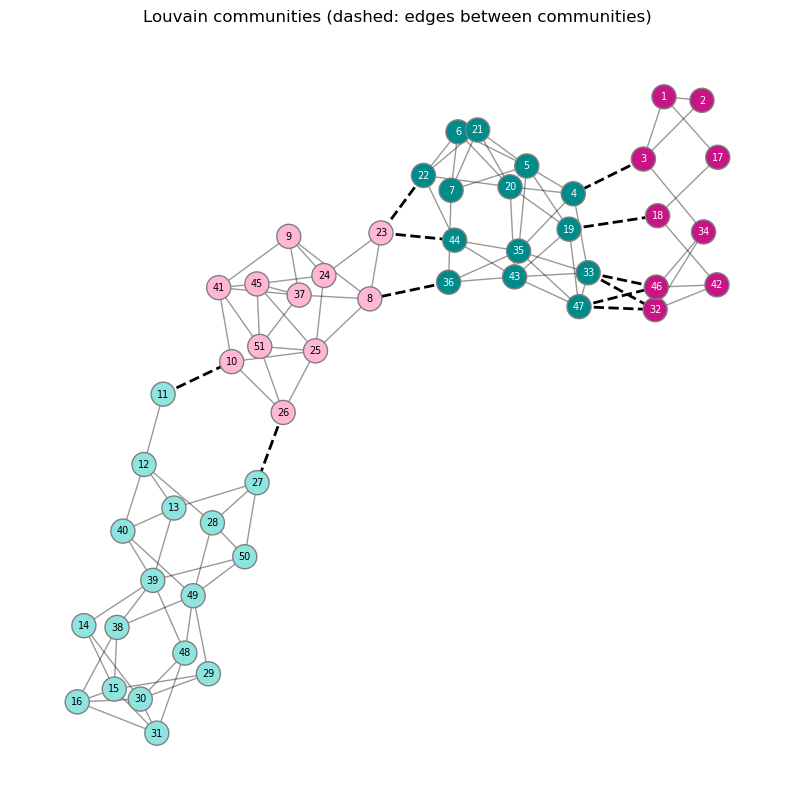

In [47]:
# Louvain method and modularity computation

runs = [louvain_communities(G, seed=s) for s in range(40)]
Qs = [modularity(G, p) for p in runs]
best = runs[Qs.index(max(Qs))]

print("Q over 40 runs: min", round(min(Qs), 3), "mean", round(np.mean(Qs), 3), "max", round(max(Qs), 3))
print("number of communities in the 40 runs:", [len(p) for p in runs])
for c in sorted(best, key=min):
    print(len(c), sorted(c))

null_Q = []
for s in range(200):
    H = G.copy()
    nx.double_edge_swap(H, nswap=10 * m, max_tries=100 * m, seed=s)
    null_Q.append(modularity(H, louvain_communities(H, seed=0)))

print("Q in 200 randomised networks: mean", round(np.mean(null_Q), 3), "±", round(np.std(null_Q), 3), "| max", round(max(null_Q), 3))
print("Q in real network (mean of 40 runs):", round(np.mean(Qs), 3))

colors = ["#C71585", "#008B8B", "#7A174B", "#005A57"]
colors = ["#C71585", "#008B8B", "#FFB7D5", "#8EE5E0"]
dark_nodes = [v for v in G if cid[v] in (0, 1)]
light_nodes = [v for v in G if cid[v] in (2, 3)]
inside = [e for e in G.edges() if cid[e[0]] == cid[e[1]]]
plt.figure(figsize=(10, 10))
nx.draw_networkx_edges(G, position, edgelist=inside, alpha=0.4)
nx.draw_networkx_edges(G, position, edgelist=inter, width=2, style="dashed", edge_color="black")
nx.draw_networkx_nodes(G, position, node_color=[colors[cid[v]] for v in G], node_size=300, edgecolors="grey")
nx.draw_networkx_labels(G, position, labels={v: v for v in dark_nodes}, font_size=7, font_color="white")
nx.draw_networkx_labels(G, position, labels={v: v for v in light_nodes}, font_size=7, font_color="black")
plt.title("Louvain communities (dashed: edges between communities)")
plt.axis("off")
plt.savefig("fig_communities.png", dpi=150, bbox_inches="tight")
plt.show()

Q: Does the network contain groups of nodes that are more strongly
connected to one another than to the rest of the network? If so, how convincing is this structure, and which
nodes or connections are particularly relevant to your interpretation?

A: The network does contain some groups of nodes that have a stronger connection to each other than the rest. With runnung Louvain 40 times Q lies within 0.608 and 0.625 (mean 0.615) indicating stable partitiions. However the number of groups is not unique, since sometimes also 5 groups are found. The best partition with Q 0.625 has four communities. Compared to 200 randomly rewired but degree preserving networks Q is 0.408 ± 0.018 (maximum 0.461)so the real network with mean Q of 0.615 is far above so we can conclude the structure is not explained by the degree alone.

The modular structure is convincingsince its stable over mmultiple runs and far above what random networks with the same degrees give however exact number of groups as well as the boundary nodes are not uniquely determined.


###  Network characteristics

                          C      L  diameter  max degree
observed              0.238  5.042     12.00        6.00
random G(n,m)         0.082  2.803      5.74        9.10
degree-preserving     0.063  2.802      5.13        6.00
ring lattice (k=4)    0.500  6.760     13.00        4.00
Watts-Strogatz p=0.1  0.375  3.885      7.93        5.58
C/C_random: 2.9 | L/L_random: 1.8
sigma: 1.61 | omega: 0.08
ln(n)/ln(<k>): 2.69 | observed L: 5.04
      C(p)/C(0)  L(p)/L(0)
p                         
0.00      1.000      1.000
0.01      0.974      0.900
0.03      0.927      0.768
0.10      0.738      0.567
0.30      0.419      0.472
1.00      0.140      0.431
observed: C/C_lattice = 0.476 | L/L_lattice = 0.746


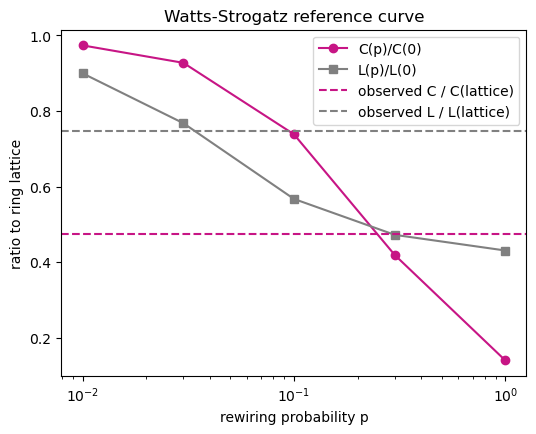

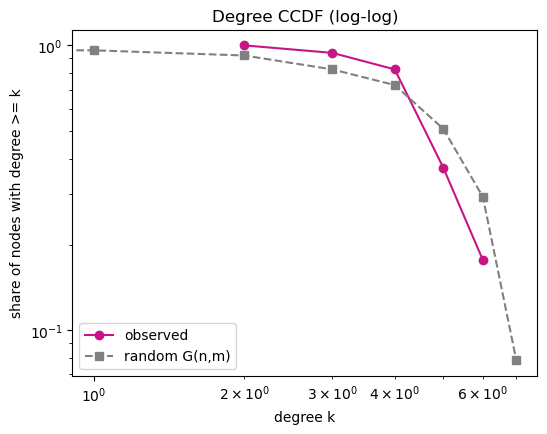

max degree: observed 6 | G(n,m) 9.0 | share of random networks with max degree <= 6: 0.0
max degree / mean degree: 1.39


In [48]:
def measures(H):
    return [nx.average_clustering(H), nx.average_shortest_path_length(H), nx.diameter(H), max(d for _, d in H.degree())]

def average_over(make, reps=100):
    out, s = [], 0
    while len(out) < reps:
        H = make(s); s += 1
        if nx.is_connected(H):
            out.append(measures(H))
    return np.mean(out, axis=0)

def swapped(s):
    H = G.copy()
    nx.double_edge_swap(H, nswap=10 * m, max_tries=100 * m, seed=s)
    return H

models = {"observed": None,
          "random G(n,m)": lambda s: nx.gnm_random_graph(n, m, seed=s),
          "degree-preserving": swapped,
          "ring lattice (k=4)": lambda s: nx.watts_strogatz_graph(n, 4, 0, seed=s),
          "Watts-Strogatz p=0.1": lambda s: nx.watts_strogatz_graph(n, 4, 0.1, seed=s)}

table = {}
for name, make in models.items():
    if make is None:
        table[name] = measures(G)
    else:
        table[name] = average_over(make, 1 if name.startswith("ring") else 100)
table = pd.DataFrame(table, index=["C", "L", "diameter", "max degree"]).T.round(3)
print(table)

C, L = measures(G)[:2]
C_rand, L_rand = table.loc["random G(n,m)", ["C", "L"]]
C_latt, L_latt = table.loc["ring lattice (k=4)", ["C", "L"]]

sigma = (C / C_rand) / (L / L_rand)
omega = L_rand / L - C / C_latt
print("C/C_random:", round(C / C_rand, 2), "| L/L_random:", round(L / L_rand, 2))
print("sigma:", round(sigma, 2), "| omega:", round(omega, 2))
print("ln(n)/ln(<k>):", round(np.log(n) / np.log(2 * m / n), 2), "| observed L:", round(L, 2))

ps = [0, 0.01, 0.03, 0.1, 0.3, 1]
sweep = []
for p in ps:
    r = average_over(lambda s: nx.watts_strogatz_graph(n, 4, p, seed=s), 50)
    sweep.append((p, r[0] / C_latt, r[1] / L_latt))
sweep = pd.DataFrame(sweep, columns=["p", "C(p)/C(0)", "L(p)/L(0)"]).set_index("p")
print(sweep.round(3))
print("observed: C/C_lattice =", round(C / C_latt, 3), "| L/L_lattice =", round(L / L_latt, 3))

plt.figure(figsize=(6, 4.5))
plt.semilogx(sweep.index[1:], sweep["C(p)/C(0)"].iloc[1:], "o-", color="#C71585", label="C(p)/C(0)")
plt.semilogx(sweep.index[1:], sweep["L(p)/L(0)"].iloc[1:], "s-", color="grey", label="L(p)/L(0)")
plt.axhline(C / C_latt, color="#C71585", linestyle="--", label="observed C / C(lattice)")
plt.axhline(L / L_latt, color="grey", linestyle="--", label="observed L / L(lattice)")
plt.xlabel("rewiring probability p")
plt.ylabel("ratio to ring lattice")
plt.title("Watts-Strogatz reference curve")
plt.legend()
plt.show()

def ccdf(H):
    d = np.array(sorted(dict(H.degree()).values()))
    ks = np.unique(d)
    return ks, np.array([(d >= k).mean() for k in ks])

plt.figure(figsize=(6, 4.5))
k_obs, p_obs = ccdf(G)
plt.loglog(k_obs, p_obs, "o-", color="#C71585", label="observed")
ks, pr = ccdf(nx.gnm_random_graph(n, m, seed=0))
plt.loglog(ks, pr, "s--", color="grey", label="random G(n,m)")
plt.xlabel("degree k")
plt.ylabel("share of nodes with degree >= k")
plt.title("Degree CCDF (log-log)")
plt.legend()
plt.show()

er_max = [max(d for _, d in nx.gnm_random_graph(n, m, seed=s).degree()) for s in range(200)]
print("max degree: observed", degree.max(), "| G(n,m)", round(np.mean(er_max), 1), "| share of random networks with max degree <= 6:", np.mean(np.array(er_max) <= 6))
print("max degree / mean degree:", round(degree.max() / degree.mean(), 2))

Q: Based on your observations, what characteristics associated with random, small‑
world, or scale‑free networks, if any, are evident in this network? Discuss the evidence for and against these characteristics, and explain the limitations of your conclusions.


A: In comparison with a ranodm network that has the same number of nodes and edges, a degree preserving randomisation, ring lattics and a Watts-Strogatz network with p = 0.1, the following observaitons can be made:

Random network with same edge and node number: Its spare and conncted withouth hubs. In the observed enzyme network the clustering effect is a bit higher, as well as the average path length and the diameter, also the degree distribution is narrowe than in this random one. So the network is clearly not random.

Small-world: High clustering and sigma = 1.61 and omega = 0.08 resemble the  small-world, however the overall idea is that there is high clustering with short distances, and in the observed network the distances are very long (almsot twice as long). 

 No rewiring probability in the Watts-Strogatz reference curve reproduces both the clustering and the path length of the network at the same time: a Watts-Strogatz network with the same clustering would have an average path length of about 3.2 instead of 5.04. The network is therefore not small-world.

Scale-free: Degrees range from 2 to 6 with the maximum being 1.4 times the mean degree also the degree distribution ends abruptly instead of having a long tail with hubs. So we can conclude it is not a scale free network.

High clustering, long distances and homogeneous degrees can be observed so it doesnt clearly indicate towards one of the tested models.

Limitations: Since our network is rather small one with only 51 nodes the coclusions are based on a small single network, which some of the properties are not defined for, small-world and scale-free describe how networks behave as they grow, and with degrees between 2 and 6 no exponent can be fitted. The indices sigma and omega also depend on the chosen reference models and none of the models contains the group structure that was observed.


### Beyond the summary

edges of the block graph (community, community, number of edges): [(0, 1, 6), (1, 2, 3), (2, 3, 2)]
degrees in the block graph: {0: 1, 1: 2, 2: 2, 3: 1}
detour: {0: 18, 1: 19, 2: 13, 4: 1}
correlation d_a vs d_b: -0.974
           min  mean  max
community                
0            0   2.1    4
1            2   3.6    4
2            5   6.3    7
3            8  10.2   12


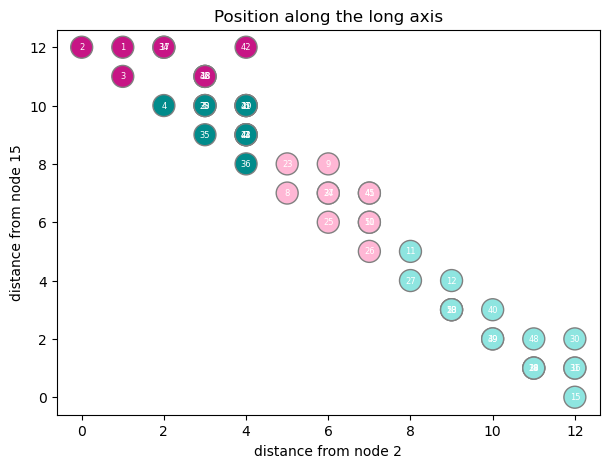

lambda2 observed: 0.048 | null: 0.777 ± 0.104 | null min: 0.388
share of null networks with lambda2 <= observed: 0.0 | ratio null/observed: 16.3


In [49]:
Q_graph = nx.Graph()
for u, v in inter:
    a, b = cid[u], cid[v]
    Q_graph.add_edge(a, b, weight=Q_graph.get_edge_data(a, b, {"weight": 0})["weight"] + 1)

print("edges of the block graph (community, community, number of edges):", sorted((a, b, d["weight"]) for a, b, d in Q_graph.edges(data=True)))
print("degrees in the block graph:", dict(Q_graph.degree()))


a, b = 2, 15
d_a = nx.single_source_shortest_path_length(G, a)
d_b = nx.single_source_shortest_path_length(G, b)
detour = pd.Series({v: d_a[v] + d_b[v] - D for v in G})

print("detour:", detour.value_counts().sort_index().to_dict())
print("correlation d_a vs d_b:", round(np.corrcoef([d_a[v] for v in G], [d_b[v] for v in G])[0, 1], 3))
axis = pd.DataFrame({"d_from_2": pd.Series(d_a), "community": pd.Series(cid)})
print(axis.groupby("community").d_from_2.agg(["min", "mean", "max"]).round(1))

plt.figure(figsize=(7, 5))
plt.scatter([d_a[v] for v in G], [d_b[v] for v in G], c=[colors[cid[v]] for v in G], s=250, edgecolors="grey")
for v in G:
    plt.annotate(str(v), (d_a[v], d_b[v]), ha="center", va="center", fontsize=6, color="white")
plt.xlabel("distance from node 2")
plt.ylabel("distance from node 15")
plt.title("Position along the long axis")
plt.show()


lam2 = nx.algebraic_connectivity(G)

null_lam = []
for s in range(200):
    H = G.copy()
    nx.double_edge_swap(H, nswap=10 * m, max_tries=100 * m, seed=s)
    null_lam.append(nx.algebraic_connectivity(H))
null_lam = np.array(null_lam)

print("lambda2 observed:", round(lam2, 3), "| null:", round(null_lam.mean(), 3), "±", round(null_lam.std(), 3), "| null min:", round(null_lam.min(), 3))
print("share of null networks with lambda2 <= observed:", np.mean(null_lam <= lam2), "| ratio null/observed:", round(null_lam.mean() / lam2, 1))

Q: Identify at least one structural feature that would be difficult to discover from thebasic network statistics alone. Show how you discovered it and explain why it matters.

A: In the visualization each node represents the distance on the x axis from node 2 and on the y axis from node 15. The nodes on the shortest path between the two ends have x+y=12 and lie on the diagonal. Nodes with the same distance lie on top of eachother.

The network is a chain of dense blocks held together narrowly. It is almost like a 1D line, which is not easily observable in the statistics (mean degree 4.31, density 0.086, clustering 0.238, no bridges).

We can see this because the four communities are connected one after the other with fewer and fewer edges between them, also every node can be placed on one line between the two ends of the network (nodes 2 and 15). And furthermore the network is much easier to cut into two parts than a random network with the same degrees (lambda2 of 0.048 compared with 0.777).

This matters because it explains the long distances (diameter 12, average path 5.04), the high betweenness of 25, 26, 27, 8 and 36 and why everything travelling between the two ends must pass through the pairs 10,11 and 26,27 for the lower half in the network.

